Goal of this homework is to create a regression model for predicting the car fuel efficiency (column 'fuel_efficiency_mpg').

In [ ]:
# Import packages
import pandas as pd

# Extract data
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv

# Saved data as variable
data = pd.read_csv("car_fuel_efficiency_2026.csv")
data.head()

--2026-11-17 08:50:03--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv’

car_fuel_efficiency 100%[===================>] 620.29K  --.-KB/s    in 0.004s  

2026-11-17 08:50:03 (144 MB/s) - ‘car_fuel_efficiency_2026.csv’ saved [635180/635180]



,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [ ]:
# Filtered data to only include relevant columns
data_filtered = data[['engine_displacement',
                    'horsepower',
                    'vehicle_weight',
                    'model_year',
                    'fuel_efficiency_mpg']]
data_filtered.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

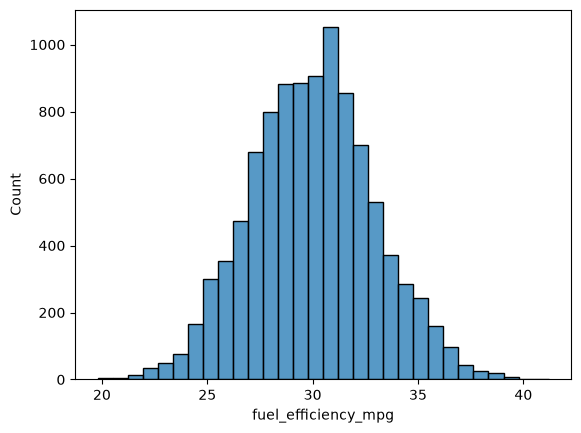

In [11]:
# EDA fuel_efficiency_mpg 
sns.histplot(data_filtered['fuel_efficiency_mpg'], bins = 30)

It doesn't have a long tail, but bell-shaped curved.

In [ ]:
# Question 1
# Check for missing values
data_filtered.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [ ]:
# Question 2
# Median for horsepower
data_filtered['horsepower'].median()

np.float64(254.0)

In [47]:
# Question 3
# Deal with missing values for the column horsepower
# Two options: fill it with 0 or with the mean of this variable horsepower.
data_filtered_option1 = data_filtered.copy()

# For computing the mean, use the training only!
data_filtered_option2 = data_filtered.copy()

# Option 1: fill with 0
data_filtered_option1['horsepower'] = data_filtered_option1['horsepower'].fillna(0)

n = len(data_filtered_option1)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

import numpy as np

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = data_filtered_option1.iloc[idx[:n_train]].reset_index(drop=True)
df_val = data_filtered_option1.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
df_test = data_filtered_option1.iloc[idx[n_train + n_val:]].reset_index(drop=True)

# Set the target variable
y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

# Remove fuel_efficiency_mpg from the features
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [48]:
df_train

,engine_displacement,horsepower,vehicle_weight,model_year
0,1900,239.0,3790,2015
1,2000,224.0,4380,1992
2,2330,286.0,4090,2022
3,2300,0.0,4150,1997
4,2340,269.0,4400,2001
...,...,...,...,...
5995,2280,242.0,4590,2018
5996,2300,0.0,4240,1984
5997,2240,255.0,4190,1989
5998,2430,254.0,4280,2020


In [49]:
y_train

array([3.51154544, 3.40452517, 3.55820113, ..., 3.35689712, 3.48431229,
       3.36729583], shape=(6000,))

In [50]:
y_val

array([3.44680789, 3.5204608 , 3.36037539, ..., 3.45315712, 3.4657359 ,
       3.45946629], shape=(2000,))

In [51]:
base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']

# Function to prepare matrix X of df generalized for any dataframe
def prepare_X(df):
    df_num = df[base]
    X = df_num.values
    return X

X_train = prepare_X(df_train)
X_train

array([[1900.,  239., 3790., 2015.],
       [2000.,  224., 4380., 1992.],
       [2330.,  286., 4090., 2022.],
       ...,
       [2240.,  255., 4190., 1989.],
       [2430.,  254., 4280., 2020.],
       [2390.,  266., 4220., 1996.]], shape=(6000, 4))

In [52]:
X_val = prepare_X(df_val)
X_val

array([[2240.,  265., 3990., 2004.],
       [2390.,  259., 4770., 2019.],
       [2360.,  265., 4320., 2018.],
       ...,
       [2390.,  264., 4550., 2017.],
       [2330.,  244., 4440., 2014.],
       [2170.,  260., 4460., 2021.]], shape=(2000, 4))

In [53]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [54]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [55]:
w0, w = train_linear_regression(X_train, y_train)
print("w0 =", w0)
print("w =", w)
y_pred = w0 + X_val.dot(w)
y_pred

w0 = -2.548879880787878
w = [-4.93996322e-05  3.99285304e-06 -1.29300047e-04  3.32220821e-03]


array([3.48332111, 3.42486629, 3.48123505, ..., 3.44668785, 3.45382835,
       3.48246563], shape=(2000,))

In [56]:
rmse(y_val, y_pred).round(3)

np.float64(0.071)

<Axes: ylabel='Count'>

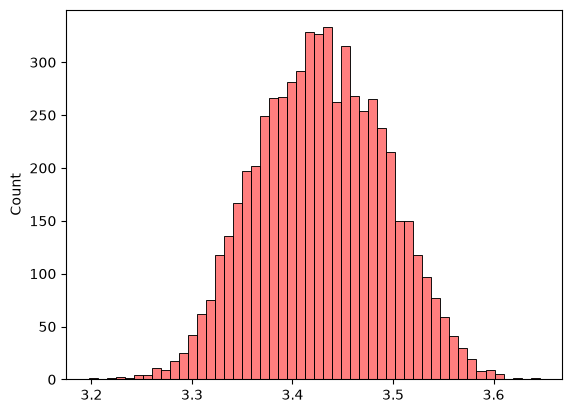

In [24]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)

<Axes: ylabel='Count'>

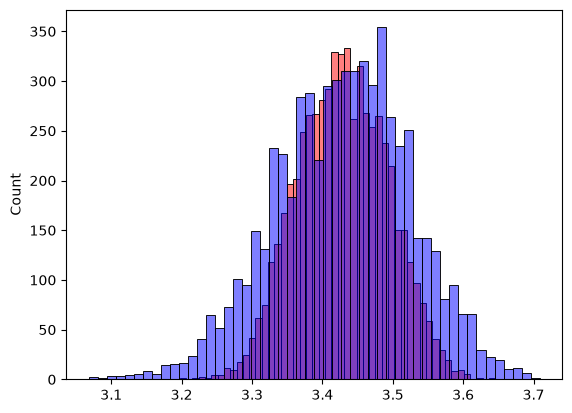

In [25]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [43]:
# Option 2: fill with the mean of this variable horsepower
n = len(data_filtered_option2)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

import numpy as np

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = data_filtered_option2.iloc[idx[:n_train]].reset_index(drop=True)
df_val = data_filtered_option2.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
df_test = data_filtered_option2.iloc[idx[n_train + n_val:]].reset_index(drop=True)

# Set the target variable
y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

# Remove fuel_efficiency_mpg from the features
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

# Fill missing values in the 'horsepower' column with the mean of the column and round to 1 decimal place
mean_hp = df_train['horsepower'].mean()

for df in [df_train, df_val, df_test]:
    df['horsepower'] = df['horsepower'].fillna(mean_hp).round(1)
df_train

,engine_displacement,horsepower,vehicle_weight,model_year
0,1900,239.0,3790,2015
1,2000,224.0,4380,1992
2,2330,286.0,4090,2022
3,2300,254.5,4150,1997
4,2340,269.0,4400,2001
...,...,...,...,...
5995,2280,242.0,4590,2018
5996,2300,254.5,4240,1984
5997,2240,255.0,4190,1989
5998,2430,254.0,4280,2020


In [ ]:
X_train = prepare_X(df_train)
X_val = prepare_X(df_val)

In [45]:
w0, w = train_linear_regression(X_train, y_train)
print("w0 =", w0)
print("w =", w)
y_pred = w0 + X_val.dot(w)
y_pred

w0 = -2.545691982110709
w = [-3.44244899e-05 -1.93841014e-04 -1.27256523e-04  3.32438034e-03]


array([3.48013397, 3.42673896, 3.4805497 , ..., 3.44711743, 3.4570848 ,
       3.48021679], shape=(2000,))

In [46]:
rmse(y_val, y_pred).round(3)

np.float64(0.071)

In [57]:
print("Option 1: Fill missing values with 0. RMSE: np.float64(0.071)")
print("Option 2: Fill missing values with the mean of horsepower from train dataset. RMSE: np.float64(0.071)")

print("Conclusions: Both are have the same performance and same result of RMSE.")

Option 1: Fill missing values with 0. RMSE: np.float64(0.071)
Option 2: Fill missing values with the mean of horsepower from train dataset. RMSE: np.float64(0.071)
Conclusions: Both are have the same performance and same result of RMSE.


In [ ]:
# Question 4: train a regularized linear regression
# For this question, fill the NAs with 0.
# Try different values of r from this list: [0, 0.01, 0.1, 1, 5, 10, 100].
# Use RMSE to evaluate the model on the validation dataset.
# Round the RMSE scores to 4 decimal digits. This keeps the small but real regularization differences visible instead of turning several choices into a tie.
# Which r gives the best RMSE?
data_filtered['horsepower'] = data_filtered['horsepower'].fillna(0)

n = len(data_filtered)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = data_filtered.iloc[idx[:n_train]].reset_index(drop=True)
df_val = data_filtered.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
df_test = data_filtered.iloc[idx[n_train + n_val:]].reset_index(drop=True)

# Set the target variable
y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

# Remove fuel_efficiency_mpg from the features
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [60]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [63]:
r_list = [0, 0.01, 0.1, 1, 5, 10, 100]

X_train = prepare_X(df_train)
X_val = prepare_X(df_val)

for r in r_list:
    w0, w = train_linear_regression_reg(X_train, y_train, r = r)
    y_pred = w0 + X_val.dot(w)
    rmse_value = rmse(y_val, y_pred).round(4)
    
    print("r =", r)
    print("w0 =", w0)
    print("w =", w)
    print("y_pred =", y_pred)
    print("RMSE =", rmse_value)
    print("-----------------------------")
    

r = 0
w0 = -2.548879880787878
w = [-4.93996322e-05  3.99285304e-06 -1.29300047e-04  3.32220821e-03]
y_pred = [3.48332111 3.42486629 3.48123505 ... 3.44668785 3.45382835 3.48246563]
RMSE = 0.0715
-----------------------------
r = 0.01
w0 = -2.456525696928604
w = [-4.98423130e-05  6.93469345e-06 -1.29521580e-04  3.27665694e-03]
y_pred = [3.48329462 3.42389969 3.48044462 ... 3.4458758  3.45314505 3.48157694]
RMSE = 0.0715
-----------------------------
r = 0.1
w0 = -1.8524448492907521
w = [-5.27378508e-05  2.61770209e-05 -1.30970604e-04  2.97871000e-03]
y_pred = [3.48312141 3.41757725 3.47527451 ... 3.44056425 3.44867562 3.47576406]
RMSE = 0.0717
-----------------------------
r = 1
w0 = -0.535529553803343
w = [-5.90502126e-05  6.81259006e-05 -1.34129514e-04  2.32917626e-03]
y_pred = [3.4827438  3.40379414 3.4640035  ... 3.42898491 3.43893212 3.46309181]
RMSE = 0.0727
-----------------------------
r = 5
w0 = -0.1287451934306354
w = [-6.10000402e-05  8.10835615e-05 -1.35105241e-04  2.1285405

In [64]:
print("If multiple options give the same best RMSE, select the smallest r.")
print("Because r = 0 and r = 0.01 give the same best RMSE, select the smallest r which is r = 0.")

If multiple options give the same best RMSE, select the smallest r.
Because r = 0 and r = 0.01 give the same best RMSE, select the smallest r which is r = 0.


In [80]:
# Question 5
# Try different seed values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9].
# For each seed, do the train/validation/test split with 60%/20%/20% distribution.
# Fill the missing values with 0 and train a model without regularization.
# For each seed, evaluate the model on the validation dataset and collect the RMSE scores.
# What's the standard deviation of all the scores? To compute the standard deviation, use np.std.
# Round the result to 3 decimal digits (round(std, 3))

seed_list = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
rmse_scores = []

def split_data(df, seed):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    train = df.iloc[idx[:n_train]].reset_index(drop=True)
    val = df.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
    test = df.iloc[idx[n_train + n_val:]].reset_index(drop=True)

    return train, val, test

for seed in seed_list:
    df_train, df_val, df_test = split_data(data_filtered, seed)

    # Set the target variable
    y_train = df_train.fuel_efficiency_mpg.values
    y_val = df_val.fuel_efficiency_mpg.values
    y_test = df_test.fuel_efficiency_mpg.values

    # Remove fuel_efficiency_mpg from the features
    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    X_train = prepare_X(df_train)
    X_val = prepare_X(df_val)

    w0, w = train_linear_regression(X_train, y_train)
    y_pred = w0 + X_val.dot(w)
    rmse_value = rmse(y_val, y_pred)
    rmse_scores.append(rmse_value)

    print("seed =", seed)
    print("w0 =", w0)
    print("w =", w)
    print("y_pred =", y_pred)
    print("RMSE =", rmse_value)
    print("-----------------------------")

std_rmse = round(np.std(rmse_scores), 3)
print("Standard deviation of RMSE scores:", std_rmse)

seed = 0
w0 = -150.42885945053604
w = [-0.00130691 -0.00017882 -0.00409437  0.10050366]
y_pred = [31.27803437 32.21594957 32.64737498 ... 30.33831921 31.03830055
 33.35092973]
RMSE = 2.239204143046126
-----------------------------
seed = 1
w0 = -151.61231559524532
w = [-1.44861835e-03 -2.78044732e-05 -4.01829035e-03  1.01103358e-01]
y_pred = [30.00306313 29.83772344 31.77651009 ... 27.54058839 31.24866098
 28.74861612]
RMSE = 2.2021128210838845
-----------------------------
seed = 2
w0 = -152.84068112584038
w = [-0.00134353 -0.00025474 -0.00404     0.10165705]
y_pred = [30.74215319 25.74612279 29.1622787  ... 29.51086867 27.15890573
 30.54115284]
RMSE = 2.1634197787530947
-----------------------------
seed = 3
w0 = -152.33298096679098
w = [-0.00144805  0.00017049 -0.00383872  0.10103501]
y_pred = [29.79729198 30.10767631 32.08226514 ... 27.69441211 31.3047681
 30.68649195]
RMSE = 2.2043588768539224
-----------------------------
seed = 4
w0 = -158.8885681645812
w = [-0.00134773 -0.00046

In [ ]:
# Question 6
# Split the dataset like previously, use seed 9.
# Combine train and validation datasets.
# Fill the missing values with 0 and train a model with r=0.001.
# What's the RMSE on the test dataset?
def split_data(df, seed):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    train = df.iloc[idx[:n_train]].reset_index(drop=True)
    val = df.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
    test = df.iloc[idx[n_train + n_val:]].reset_index(drop=True)

    return train, val, test

data_filtered['horsepower'] = data_filtered['horsepower'].fillna(0)

df_train, df_val, df_test = split_data(data_filtered, 9)

# Combine train and validation datasets
df_train_val = pd.concat([df_train, [df_val], ignore_index = True)

# Set the target variable
y_train_val = df_train_val["fuel_efficiency_mpg"].to_numpy()
y_test = df_test["fuel_efficiency_mpg"].to_numpy()

# Remove fuel_efficiency_mpg from the features
del df_train_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

# Set the predictors variable
X_train_val = prepare_X(df_train_val)
X_test = prepare_X(df_test)

w0, w = train_linear_regression_reg(X_train_val, y_train_val, r = 0.001)
y_pred = w0 + X_test.dot(w)

print("Test RMSE:", round(rmse(y_test, y_pred), 3))

Test RMSE: 2.236
